# QFF 2026 Phase 1 - PS-P3: Quantum adder on Processor A vs B

## 1. Problem
A 1-bit quantum adder. Output is read as `carry sum`.

In [1]:
from src.problem import one_bit_adder, expected_output
from src.processors import load_processor
from src.routing import run_on
from src.visualization import draw_processor
import pandas as pd

A = load_processor("processors/processor_A.json")
B = load_processor("processors/processor_B.json")

## 2. Processor graphs

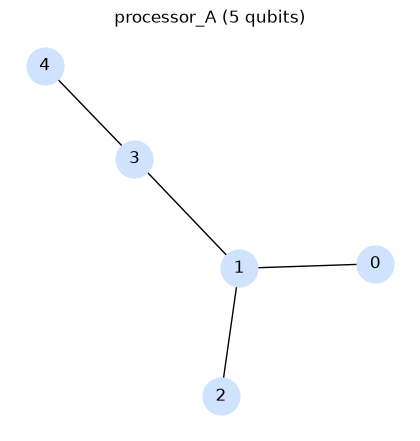

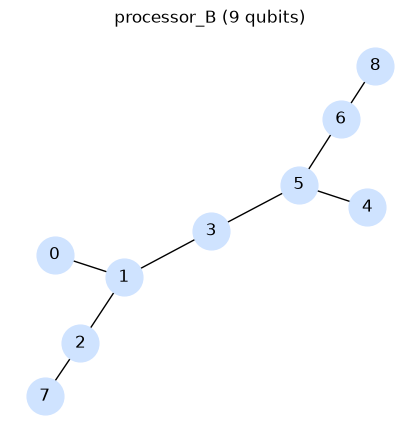

In [2]:
draw_processor(A, "results/figures/processor_A_graph.png")
draw_processor(B, "results/figures/processor_B_graph.png")

## 3. 1-bit adder: A vs B (ideal, then noisy)
Same circuit, shots, seed and transpiler settings on both.

In [3]:
rows = []
for name, proc in [("A", A), ("B", B)]:
    for noisy in (False, True):
        _, counts, m = run_on(one_bit_adder(1, 1), proc, shots=2048, noisy=noisy, seed=1)
        ok = counts.get(expected_output(1, 1), 0) / 2048
        rows.append({"processor": name, "noisy": noisy, "depth": m["depth"], "two_qubit_gates": m["two_qubit_gates"], "success_rate": ok})
table = pd.DataFrame(rows)
table.to_csv("results/tables/AB_comparison.csv", index=False)
table

,processor,noisy,depth,two_qubit_gates,success_rate
0,A,False,29,17,1.00000
1,A,True,29,17,0.86084
2,B,False,29,17,1.00000
3,B,True,29,17,0.86084


## 4. Two-bit adder: A vs B

In [4]:
import itertools
from src.problem import two_bit_adder, expected_two_bit

rows = []
for name, proc in [("A", A), ("B", B)]:
    for noisy in (False, True):
        ok = total = 0
        for a, b in itertools.product(range(4), range(4)):
            _, counts, m = run_on(two_bit_adder(a, b), proc, shots=2048, noisy=noisy, seed=1)
            ok += counts.get(expected_two_bit(a, b), 0)
            total += 2048
        rows.append({"processor": name, "noisy": noisy, "depth": m["depth"],
                     "two_qubit_gates": m["two_qubit_gates"], "success_rate": ok / total})
two_bit_table = pd.DataFrame(rows)
two_bit_table.to_csv("results/tables/two_bit_AB.csv", index=False)
two_bit_table

,processor,noisy,depth,two_qubit_gates,success_rate
0,A,False,28,21,1.000000
1,A,True,28,21,0.849060
2,B,False,31,24,1.000000
3,B,True,31,24,0.839691


## 5. Seed sweep (30 seeds, both opt levels)

In [5]:
import statistics as st
from src.routing import compile_for
from src.metrics import circuit_metrics

rows = []
for level in (0, 1):
    for name, proc in [("A", A), ("B", B)]:
        gates, depths = [], []
        for seed in range(30):
            m = circuit_metrics(compile_for(two_bit_adder(3, 3), proc, optimization_level=level, seed=seed))
            gates.append(m["two_qubit_gates"])
            depths.append(m["depth"])
        rows.append({"opt_level": level, "processor": name,
                     "2q_mean": round(st.mean(gates), 1), "2q_sd": round(st.stdev(gates), 1),
                     "2q_min": min(gates), "2q_max": max(gates),
                     "depth_mean": round(st.mean(depths), 1)})
seed_table = pd.DataFrame(rows)
seed_table.to_csv("results/tables/seed_sweep.csv", index=False)
seed_table

,opt_level,processor,2q_mean,2q_sd,2q_min,2q_max,depth_mean
0,0,A,21.2,0.8,21,24,29.0
1,0,B,24.4,1.0,24,27,31.9
2,1,A,10.0,0.0,10,10,20.0
3,1,B,10.0,0.0,10,10,19.2


## 6. Design comparison: ripple vs Draper

In [6]:
from src.problem import draper_adder_2bit

rows = []
for dname, fn in [("ripple", two_bit_adder), ("draper", draper_adder_2bit)]:
    for level in (0, 1):
        for pname, proc in [("A", A), ("B", B)]:
            gates, depths = [], []
            for seed in range(30):
                m = circuit_metrics(compile_for(fn(3, 3), proc, level, seed))
                gates.append(m["two_qubit_gates"])
                depths.append(m["depth"])
            ok = tot = 0
            for a, b in itertools.product(range(4), range(4)):
                _, c, _ = run_on(fn(a, b), proc, shots=2048, noisy=True, optimization_level=level, seed=1)
                ok += c.get(expected_two_bit(a, b), 0)
                tot += 2048
            rows.append({"design": dname, "opt_level": level, "processor": pname,
                         "2q_mean": round(st.mean(gates), 1), "2q_sd": round(st.stdev(gates), 1),
                         "depth_mean": round(st.mean(depths), 1), "noisy_success": round(ok / tot, 3)})
design_table = pd.DataFrame(rows)
design_table.to_csv("results/tables/design_comparison.csv", index=False)
design_table

,design,opt_level,processor,2q_mean,2q_sd,depth_mean,noisy_success
0,ripple,0,A,21.2,0.8,29.0,0.849
1,ripple,0,B,24.4,1.0,31.9,0.840
2,ripple,1,A,10.0,0.0,20.0,0.903
3,ripple,1,B,10.0,0.0,19.2,0.903
4,draper,0,A,23.1,1.5,45.5,0.830
5,draper,0,B,23.1,1.5,45.5,0.830
6,draper,1,A,19.0,0.0,37.6,0.847
7,draper,1,B,19.0,0.0,37.1,0.845


## 7. Placement sweep (does layout choice matter?)

In [7]:
import random
from qiskit import transpile
from src.processors import get_coupling_map
random.seed(0)

def layout_sweep(fn, proc, nq, samples=300):
    cm = get_coupling_map(proc)
    perms = list(itertools.permutations(range(proc["num_qubits"]), nq))
    if len(perms) > samples:
        perms = random.sample(perms, samples)
    counts = []
    for lay in perms:
        qc = transpile(fn(3, 3), coupling_map=cm, basis_gates=proc["basis_gates"],
                       initial_layout=list(lay), optimization_level=0, seed_transpiler=1)
        counts.append(circuit_metrics(qc)["two_qubit_gates"])
    return {"min": min(counts), "mean": round(st.mean(counts), 1), "max": max(counts), "layouts": len(counts)}

rows = [{"processor": n, **layout_sweep(two_bit_adder, p, 5)} for n, p in [("A", A), ("B", B)]]
layout_table = pd.DataFrame(rows)
layout_table.to_csv("results/tables/layout_sweep.csv", index=False)
layout_table

,processor,min,mean,max,layouts
0,A,12,18.6,24,120
1,B,15,28.5,45,300


## 8. Scaling trend: 1-bit, 2-bit, 3-bit
A fits up to 2-bit (5 qubits). B fits 3-bit (8 qubits). We measure how gate count grows with size.

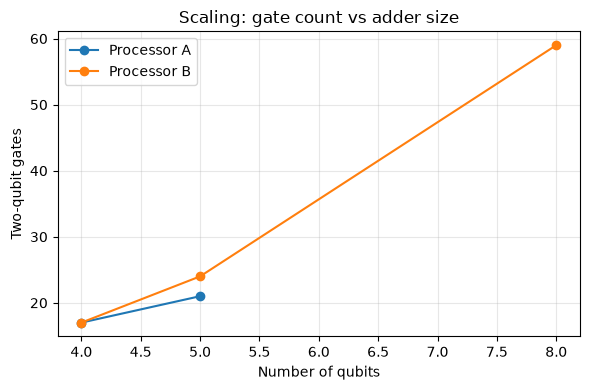

In [8]:
from src.problem import three_bit_adder, expected_three_bit
import matplotlib.pyplot as plt

rows = []
# 1-bit on A and B (from section 3 data, reusing seed=1)
for name, proc in [("A", A), ("B", B)]:
    _, _, m1 = run_on(one_bit_adder(1, 1), proc, shots=2048, noisy=False, seed=1)
    rows.append({"processor": name, "adder_size": "1-bit", "qubits": 4,
                 "two_qubit_gates": m1["two_qubit_gates"], "depth": m1["depth"]})
# 2-bit on A and B
for name, proc in [("A", A), ("B", B)]:
    _, _, m2 = run_on(two_bit_adder(3, 3), proc, shots=2048, noisy=False, seed=1)
    rows.append({"processor": name, "adder_size": "2-bit", "qubits": 5,
                 "two_qubit_gates": m2["two_qubit_gates"], "depth": m2["depth"]})
# 3-bit on B only (does not fit on A)
_, _, m3 = run_on(three_bit_adder(7, 7), B, shots=2048, noisy=False, seed=1)
rows.append({"processor": "B", "adder_size": "3-bit", "qubits": 8,
             "two_qubit_gates": m3["two_qubit_gates"], "depth": m3["depth"]})

scaling_table = pd.DataFrame(rows)
scaling_table.to_csv("results/tables/scaling_trend.csv", index=False)
scaling_table

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
for name, proc_data in scaling_table.groupby("processor"):
    proc_data = proc_data.sort_values("qubits")
    ax.plot(proc_data["qubits"], proc_data["two_qubit_gates"], "o-", label=f"Processor {name}")
ax.set_xlabel("Number of qubits")
ax.set_ylabel("Two-qubit gates")
ax.set_title("Scaling: gate count vs adder size")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/figures/scaling_trend.png", dpi=150)
plt.show()

## 9. Noise sensitivity analysis
Run the 2-bit adder on A and B with increasing 2Q error rates to see if B's extra gates hurt more under noise.

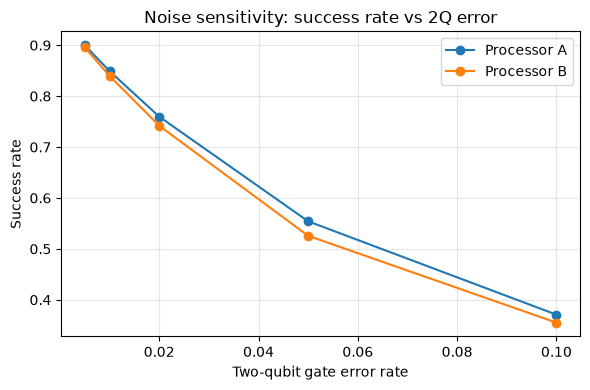

In [9]:
from src.processors import get_noise_model
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit_aer import AerSimulator
from qiskit import transpile
import matplotlib.pyplot as plt

noise_rates = [0.005, 0.01, 0.02, 0.05, 0.10]
rows = []
for name, proc in [("A", A), ("B", B)]:
    for rate in noise_rates:
        model = NoiseModel()
        model.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ["x", "sx"])
        model.add_all_qubit_quantum_error(depolarizing_error(rate, 2), ["cx"])
        model.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.02, 0.98]]))
        sim = AerSimulator(noise_model=model)
        ok = tot = 0
        for a, b in itertools.product(range(4), range(4)):
            compiled = compile_for(two_bit_adder(a, b), proc, optimization_level=0, seed=1)
            counts = sim.run(compiled, shots=2048, seed_simulator=1).result().get_counts()
            ok += counts.get(expected_two_bit(a, b), 0)
            tot += 2048
        rows.append({"processor": name, "two_qubit_error": rate, "success_rate": ok / tot})

noise_table = pd.DataFrame(rows)
noise_table.to_csv("results/tables/noise_sensitivity.csv", index=False)
noise_table

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
for name, data in noise_table.groupby("processor"):
    data = data.sort_values("two_qubit_error")
    ax.plot(data["two_qubit_error"], data["success_rate"], "o-", label=f"Processor {name}")
ax.set_xlabel("Two-qubit gate error rate")
ax.set_ylabel("Success rate")
ax.set_title("Noise sensitivity: success rate vs 2Q error")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/figures/noise_sensitivity.png", dpi=150)
plt.show()

## 10. Multiplier (B only)
A 2-bit multiplier (6 qubits) — does not fit on A (5 qubits). Runs on B only.

In [10]:
from src.problem import two_bit_multiplier, expected_mult

rows = []
for noisy in (False, True):
    ok = total = 0
    for a, b in itertools.product(range(4), range(4)):
        _, counts, m = run_on(two_bit_multiplier(a, b), B, shots=2048, noisy=noisy, seed=1)
        ok += counts.get(expected_mult(a, b), 0)
        total += 2048
    rows.append({"processor": "B", "noisy": noisy, "depth": m["depth"],
                 "two_qubit_gates": m["two_qubit_gates"], "success_rate": ok / total})
mult_table = pd.DataFrame(rows)
mult_table.to_csv("results/tables/multiplier_AB.csv", index=False)
mult_table

,processor,noisy,depth,two_qubit_gates,success_rate
0,B,False,72,48,1.000000
1,B,True,72,48,0.777527


## 11. Explanation

We ran the same 2-bit modular adder (5 qubits) on Processor A and Processor B
with identical noise, 2048 shots, and the same transpiler settings.

At optimization level 0, Processor B needed more two-qubit gates than A
(mean 24.4 vs 21.2 over 30 seeds) and slightly more depth (31.9 vs 29.0).
Single-seed noisy success was 0.849 on A and 0.840 on B.

Why: the carry qubit (qubit 4) must interact with qubits 0, 2 and 3.
With the default placement, these sit closer together on A than on B,
so the transpiler inserted more SWAPs on B. Each SWAP costs 3 two-qubit gates.
More two-qubit gates mean more noisy operations, which fits B's lower success rate.

Noise vs wiring: both processors use identical noise, so the level-0
difference comes from connectivity and routing.

At optimization level 1, both processors needed 10 two-qubit gates. A better
placement removed almost all routing cost, so this small circuit does not
show a lasting architecture advantage. The compiler setting matters as much
as the wiring.

The placement sweep shows why: on B (9 qubits), the spread of possible
two-qubit gate counts is much wider (15 to 45) than on A (12 to 24).
With more qubits there are more bad places to put the circuit, so the
default placement is more likely to land on a poor choice.

The scaling trend shows the gap grows with problem size: A handles up to
2-bit adders (5 qubits), while B can fit 3-bit adders (8 qubits) but at
higher routing cost. This suggests the wiring disadvantage becomes more
pronounced as circuits grow.

The noise sensitivity analysis shows whether B's extra gates translate to
steeper degradation as noise increases. The multiplier experiment extends
the benchmark beyond adders to a second arithmetic operation.

## 12. Scope and Future Work

This project benchmarks two adder designs (ripple-carry and Draper QFT) on two small simulated processors. The results show that wiring affects routing cost at low optimization levels, and that this effect grows with circuit size.

Future work could extend this by:
- Testing on real quantum hardware (IBM Quantum backends)
- Adding more circuit families (Grover, QFT, variational circuits)
- Scaling to larger processors (15-25 qubits) where routing effects are more pronounced
- Using realistic noise models calibrated from actual device properties